# Rijden de Treinen Analysis

1. Download and unzip `.csv.gz` files

In [1]:
# 2. Put stations data into stations table in DuckDB

import duckdb

db = duckdb.connect("data/duckdb_treinen.db")

db.sql("""
CREATE TABLE IF NOT EXISTS stations AS
FROM "data/stations-2023-09.csv"
""")

In [ ]:
# 3. Create tables distances and distances_long

db.sql("""
CREATE TABLE distances AS
    FROM 'data/tariff-distances-2022-01.csv';
""")

db.sql("SELECT * FROM distances LIMIT 10").show()

┌─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────

In [3]:
db.sql("""
CREATE TABLE distances_long AS
UNPIVOT distances
ON COLUMNS (* EXCLUDE station)
INTO NAME other_station VALUE distance;
""")

db.sql("""
SELECT *
FROM distances_long
LIMIT 5
""").show()

┌─────────┬───────────────┬──────────┐
│ Station │ other_station │ distance │
│ varchar │    varchar    │ varchar  │
├─────────┼───────────────┼──────────┤
│ AC      │ AC            │ XXX      │
│ AC      │ AH            │ 82       │
│ AC      │ AHP           │ 83       │
│ AC      │ AHPR          │ 85       │
│ AC      │ AHZ           │ 90       │
└─────────┴───────────────┴──────────┘



In [ ]:
# 4. Put train disruptions into disruptions table in the Postgres database

db.sql("""INSTALL postgres; LOAD postgres;""")

# NEVER write password like this explicitly in real code!
conn_string = "host=localhost user=postgres password=postgres dbname=postgres"

db.sql(f"""
ATTACH IF NOT EXISTS '{conn_string}' AS postgres_db (TYPE postgres);
""")

In [9]:
db.sql("""
CREATE TABLE postgres_db.public.disruptions AS
SELECT *
FROM read_csv_auto(
    [
        'data/disruptions/disruptions-2012.csv',
        'data/disruptions/disruptions-2013.csv',
        'data/disruptions/disruptions-2014.csv',
        'data/disruptions/disruptions-2015.csv',
        'data/disruptions/disruptions-2016.csv',
        'data/disruptions/disruptions-2017.csv',
        'data/disruptions/disruptions-2018.csv',
        'data/disruptions/disruptions-2019.csv',
        'data/disruptions/disruptions-2020.csv',
        'data/disruptions/disruptions-2021.csv',
        'data/disruptions/disruptions-2022.csv',
    ],
    union_by_name = true
);
""")

In [38]:
db.sql("SELECT * FROM postgres_db.public.disruptions LIMIT 5;")

┌────────┬───────────────────────────────────┬───────────────────────────────────────────────────────────────────────────────────────┬──────────────┬───────────────────┬───────────────────┬──────────────────────────────────────────┬───────────────────────────────────┬──────────────────────────────────────────┬───────────────────────────────────┬────────────────┬─────────────────────┬─────────────────────┬──────────────────┐
│ rdt_id │             ns_lines              │                                       rdt_lines                                       │ rdt_lines_id │ rdt_station_names │ rdt_station_codes │                 cause_nl                 │             cause_en              │           statistical_cause_nl           │       statistical_cause_en        │  cause_group   │     start_time      │      end_time       │ duration_minutes │
│ int64  │              varchar              │                                        varchar                                        │   varchar

In [ ]:
# 5. Transform train services CSV files into a single Parquet file

db.sql("""
COPY (
    SELECT * FROM read_csv_auto([
        'data/services/services-2020.csv',
        'data/services/services-2021.csv',
        'data/services/services-2022.csv',
        'data/services/services-2023.csv',
        'data/services/services-2024.csv'
    ])
) TO 'data/services/services-all.parquet' (FORMAT PARQUET, COMPRESSION ZSTD);
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [16]:
# Make table services from created parquet file

db.sql("""
CREATE TABLE services AS
    FROM 'data/services/services-all.parquet';
""")

db.sql("""
SELECT *
FROM services
LIMIT 5
""").show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌────────────────┬──────────────┬──────────────┬─────────────────┬──────────────────────┬──────────────────────────────┬──────────────────────────┬───────────────────────┬─────────────┬───────────────────┬────────────────────┬─────────────────────┬────────────────────┬────────────────────────┬─────────────────────┬──────────────────────┬──────────────────────────┬──────────────────────┬───────────────────────┬──────────────────────┐
│ Service:RDT-ID │ Service:Date │ Service:Type │ Service:Company │ Service:Train number │ Service:Completely cancelled │ Service:Partly cancelled │ Service:Maximum delay │ Stop:RDT-ID │ Stop:Station code │ Stop:Station name  │  Stop:Arrival time  │ Stop:Arrival delay │ Stop:Arrival cancelled │ Stop:Departure time │ Stop:Departure delay │ Stop:Departure cancelled │ Stop:Platform change │ Stop:Planned platform │ Stop:Actual platform │
│     int64      │     date     │   varchar    │     varchar     │        int64         │           boolean            │      

In [ ]:
# 7i. How many trains departed from Amsterdam Centraal station overall

db.sql("""
SELECT COUNT(DISTINCT "Service:RDT-ID") AS total_trains
FROM services
WHERE "Stop:Station name" = 'Amsterdam Centraal'
  AND "Stop:Departure time" IS NOT NULL;
""")

┌──────────────┐
│ total_trains │
│    int64     │
├──────────────┤
│      1381845 │
└──────────────┘

In [22]:
# 7ii. Calculate the average arrival delay of different service types (Service:Type). Order results descending by average delay

db.sql("""
SELECT
    "Service:Type",
    AVG("Stop:Arrival delay") AS average_arrival_delay
FROM services
GROUP BY "Service:Type"
ORDER BY average_arrival_delay DESC;
""")

┌──────────────────────┬───────────────────────┐
│     Service:Type     │ average_arrival_delay │
│       varchar        │        double         │
├──────────────────────┼───────────────────────┤
│ Alpen Express        │    25.626923076923077 │
│ Krokus Express       │     20.90909090909091 │
│ European Sleeper     │    12.175902506323293 │
│ Nightjet             │     9.012493009863528 │
│ Eurostar             │    6.9817580516991535 │
│ Int. Trein           │     6.646307385229541 │
│ ICE International    │     5.392888787263841 │
│ Thalys               │     5.012937639253559 │
│ Nachttrein           │      4.27683615819209 │
│ Stoomtrein           │    3.6103896103896105 │
│     ·                │                    ·  │
│     ·                │                    ·  │
│     ·                │                    ·  │
│ Niet instappen       │                   0.0 │
│ Tram i.p.v. trein    │                   0.0 │
│ Metro                │                   0.0 │
│ Snelbus i.p.v. tre

In [28]:
# 7iii. What was the most common disruption cause in different years
db.sql("""
SELECT
    YEAR(start_time) AS year,
    MODE(cause_en) AS most_common_cause
FROM postgres_db.public.disruptions
WHERE cause_en IS NOT NULL
GROUP BY year
ORDER BY year;
""")

┌───────┬───────────────────┐
│ year  │ most_common_cause │
│ int64 │      varchar      │
├───────┼───────────────────┤
│  2012 │ points failure    │
│  2013 │ points failure    │
│  2014 │ broken down train │
│  2015 │ broken down train │
│  2016 │ broken down train │
│  2017 │ broken down train │
│  2018 │ broken down train │
│  2019 │ broken down train │
│  2020 │ broken down train │
│  2021 │ broken down train │
│  2022 │ broken down train │
├───────┴───────────────────┤
│ 11 rows         2 columns │
└───────────────────────────┘

In [32]:
# 7iv. How many trains started their overall service in any Amsterdam station?

db.sql("""
SELECT COUNT(DISTINCT "Service:RDT-ID") AS total_trains
FROM services
WHERE "Stop:Arrival time" IS NULL AND "Stop:Station name" LIKE 'Amsterdam%';
""")

┌──────────────┐
│ total_trains │
│    int64     │
├──────────────┤
│       892597 │
└──────────────┘

In [44]:
# 7v. What fraction of services was run to final destinations outside the Netherlands

db.sql("""
""")

In [ ]:
# 7vi. What is the largest distance between stations in the Netherlands (code NL)

db.sql("""

""")

<Axes: title={'center': 'Average daily arrival delays between train operators'}, ylabel='company'>

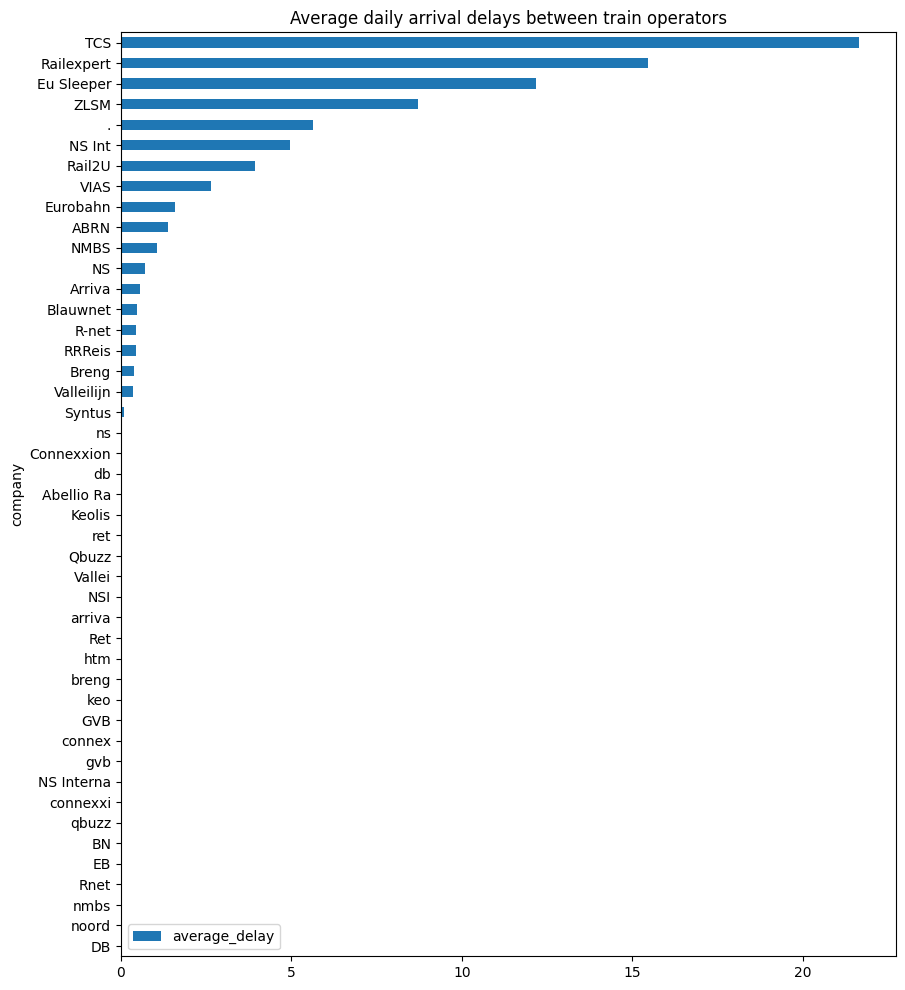

In [35]:
# 7vii. Compare the average arrival delay between different train operators (Service:Company) on a bar plot. Sort them

delays = db.sql("""
SELECT
    "Service:Company" AS company,
    AVG("Stop:Arrival delay") AS average_delay
FROM services
WHERE "Stop:Arrival delay" IS NOT NULL
GROUP BY "Service:Company"
ORDER BY average_delay
""").df()

delays.plot.barh(
    x="company",
    y="average_delay",
    title="Average daily arrival delays between train operators",
    figsize=(10, 12),
)

<Axes: title={'center': 'Disrupted services in different years'}, xlabel='year'>

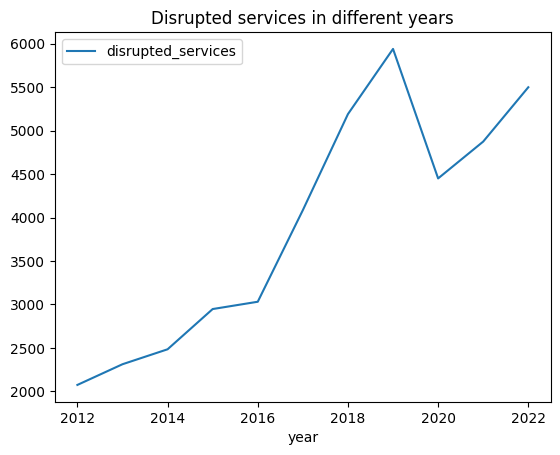

In [40]:
# 7viii. How many services were disrupted in different years, line plot

disrupted_count = db.sql("""
SELECT
    YEAR(start_time) AS year,
    COUNT(DISTINCT rdt_id) AS disrupted_services
FROM postgres_db.public.disruptions
WHERE start_time IS NOT NULL
GROUP BY year
ORDER BY year
""").df()

disrupted_count.plot.line(
    x="year", y="disrupted_services", title="Disrupted services in different years"
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

<Axes: title={'center': 'Cancelled serices (fraction)'}, xlabel='year'>

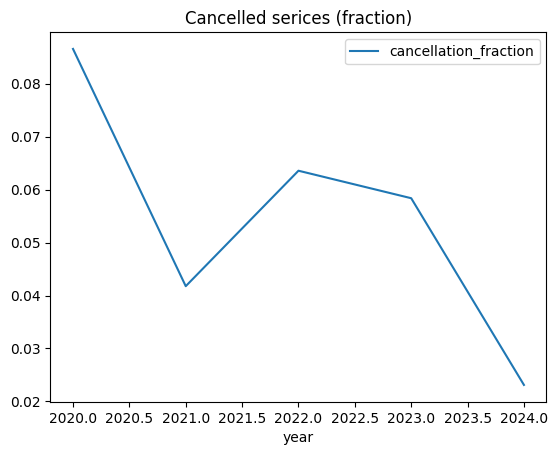

In [ ]:
# 7ix. What fraction of all services were cancelled (Service:Completely cancelled) in different years, line plot

cancelled = db.sql("""
SELECT
    YEAR("Service:Date") AS year,
    COUNT(DISTINCT CASE
        WHEN "Service:Completely cancelled" = TRUE
        THEN "Service:RDT-ID"
    END) * 1.0 / COUNT(DISTINCT "Service:RDT-ID") AS cancellation_fraction
FROM services
GROUP BY year
ORDER BY year
""").df()

cancelled.plot.line(
    x="year", y="cancellation_fraction", title="Cancelled serices (fraction)"
)

In [46]:
# 8. Create table station_connections, with columns Service:RDT-ID, start_station_code and end_station_code (pair of stations on a route), and distance between them

db.sql("""
CREATE TABLE station_connections AS
WITH connections AS (
    SELECT
        "Service:RDT-ID" AS service_id,
        "Stop:Station code" AS start_station_code,
        LEAD("Stop:Station code") OVER (
            PARTITION BY "Service:RDT-ID"
            ORDER BY "Stop:Departure time" NULLS LAST
        ) AS end_station_code
    FROM services
)
SELECT DISTINCT
    c.service_id,
    c.start_station_code,
    c.end_station_code,
    CAST(d.distance AS INTEGER) AS distance
FROM connections c
JOIN distances_long d
    ON d.Station = c.start_station_code
   AND d.other_station = c.end_station_code
WHERE c.end_station_code IS NOT NULL
  AND c.start_station_code <> c.end_station_code
  AND TRY_CAST(d.distance AS INTEGER) IS NOT NULL;
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [47]:
db.sql("SELECT * FROM station_connections LIMIT 5")

┌────────────┬────────────────────┬──────────────────┬──────────┐
│ service_id │ start_station_code │ end_station_code │ distance │
│   int64    │      varchar       │     varchar      │  int32   │
├────────────┼────────────────────┼──────────────────┼──────────┤
│   13740387 │ ASDZ               │ SHL              │       11 │
│   13742183 │ EGHM               │ LG               │        3 │
│   13752358 │ CAS                │ HLO              │        7 │
│   13752576 │ WFM                │ BF               │        5 │
│   13756999 │ ASN                │ GN               │       28 │
└────────────┴────────────────────┴──────────────────┴──────────┘

In [48]:
# What is the largest distance between a pair of stations

db.sql("SELECT MAX(distance) AS largest_distance FROM station_connections")

┌──────────────────┐
│ largest_distance │
│      int32       │
├──────────────────┤
│              421 │
└──────────────────┘

<Axes: title={'center': 'Inner-station distances run by trains'}, ylabel='Frequency'>

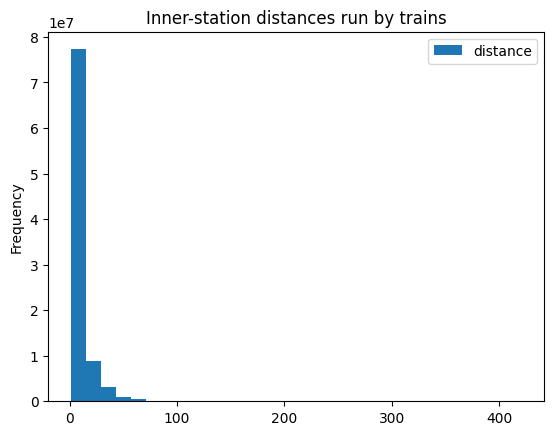

In [51]:
# Plot a histogram of inter-station distances run by trains

inner_distances = db.sql("""SELECT distance FROM station_connections""").df()

inner_distances.plot.hist(
    column="distance", title="Inner-station distances run by trains", bins=30
)